# Phân tích & Trực quan hóa Kết quả Thực nghiệm Toàn diện
**Đề tài:** Tái hiện bài báo khoa học *"A Hybrid Crypto-Steganography Framework for Secure Image Transfer"* (Snehal Dipak Raut et al., ICITSC 2025, pp. 175–182) từ MATLAB R2024a sang Python 3.12.  
**Học phần:** CT204 – An toàn và Bảo mật Thông tin  
**Kho mã nguồn & dữ liệu thực nghiệm:** [https://github.com/NguyenMinhTri24072005/CT204-hybrid-crypto-stego](https://github.com/NguyenMinhTri24072005/CT204-hybrid-crypto-stego)

---

### Nội dung Notebook (12 Biểu đồ & Bảng Phân tích Chuyên sâu)
1. **Tải dữ liệu tự động từ GitHub (`git clone`)** — chạy độc lập trên Google Colab, Kaggle hoặc Jupyter cục bộ.
2. **Kiểm định toàn vẹn dữ liệu (`24,000` lượt chạy = `8,000` ảnh Linnaeus 5 × `3` thuật toán)** & xác nhận khôi phục nguyên bản `MSE == 0` đạt `100%`.
3. **Bảng đối chiếu trực diện với Bảng 2 của bài báo gốc** (kèm độ lệch tuyệt đối $\Delta$ và sai số tương đối `%`).
4. **Hình 1:** Trực quan hóa luồng biến đổi ảnh mẫu (Cover $\rightarrow$ Secret $\rightarrow$ Encrypted $\rightarrow$ Stego $\rightarrow$ Bản đồ sai số LSB khuếch đại $\times 85$ $\rightarrow$ Recovered).
5. **Hình 2:** Hiển thị trực tiếp bộ đồ thị tái hiện **Figure 4** & **Figure 5** của bài báo gốc.
6. **Hình 3:** So sánh chất lượng thị giác trung bình (`MSE`, `PSNR`, `SSIM`) giữa **Thực nghiệm Python (8,000 ảnh)**, **Bài báo (MATLAB)** và **Giá trị lý thuyết 1-LSB**.
7. **Hình 4:** Phân phối thống kê chi tiết (Violin + Boxplot + Histogram KDE) của `MSE`, `PSNR`, `SSIM` trên 24,000 mẫu.
8. **Hình 5:** Phân tích tốc độ mã hóa (`EncTime`) — Thang Logarit, Hệ số tăng tốc (`Speedup ×`), và Phân phối ECDF thực tế.
9. **Hình 6:** Phân tích an toàn vi sai & thống kê bản mã (`NPCR`, `UACI`, `Correlation`) đối chiếu ngưỡng lý thuyết $255/256 = 99.6094\%$.
10. **Hình 7:** Giải mã điểm mù học thuật của Bảng 2 (`BM-08`) — Đối chứng song song nhóm chỉ số **Bản mã (`*_enc`)** vs. **Ảnh giấu tin (`*_stego`)**.
11. **Hình 8:** Phân tích chuyên sâu theo **5 lớp đối tượng Linnaeus 5** (`berry`, `bird`, `dog`, `flower`, `other`) — Heatmap & Boxplot đa biến.
12. **Hình 9:** Kiểm chứng độ ổn định `train` (6,000 ảnh) vs. `test` (2,000 ảnh) & Quy luật vật lý `Entropy_stego` vs. `SSIM` (Hexbin Joint Plot).
13. **Hình 10:** Đánh đổi Dung lượng – Chất lượng (Capacity–Distortion Trade-off): Chế độ **1-LSB (`156×156`)** vs. **3-LSB Auto Scale-up (`246×300`)**.
14. **Hình 11:** Biểu đồ Mạng nhện Đa tiêu chí (**Radar Chart**) & Tổng kết khuyến nghị ứng dụng cho Báo cáo CT204.

## 1. Clone Kho Dữ liệu từ GitHub & Thiết lập Môi trường
Cell dưới đây tự động `git clone` repository `https://github.com/NguyenMinhTri24072005/CT204-hybrid-crypto-stego.git` (hoặc `git pull` nếu đã clone trước đó) để nạp toàn bộ file số liệu CSV và ảnh kết quả trực tiếp từ GitHub. Có thể chạy ngay trên **Google Colab** mà không cần cấu hình thủ công.

In [1]:
import math
import subprocess
import tempfile
import warnings
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    display = globals().get("display", print)

warnings.filterwarnings("ignore")

REPO_URL = "https://github.com/NguyenMinhTri24072005/CT204-hybrid-crypto-stego.git"

# Trên Google Colab clone thẳng vào /content; trên máy cục bộ clone vào thư mục tạm để không lồng repo Git
CLONE_ROOT = Path("/content") if Path("/content").is_dir() else Path(tempfile.gettempdir())
CLONED_REPO_DIR = CLONE_ROOT / "CT204-hybrid-crypto-stego"


def fetch_results_from_github(repo_url: str = REPO_URL, clone_dir: Path = CLONED_REPO_DIR) -> Path:
    """Clone (hoặc cập nhật) dữ liệu thực nghiệm từ GitHub; fallback sang thư mục cục bộ nếu chạy offline."""
    if (clone_dir / ".git").is_dir():
        proc = subprocess.run(
            ["git", "-C", str(clone_dir), "pull", "--ff-only"],
            capture_output=True,
            text=True,
        )
        candidate = clone_dir / "SOURCES" / "results"
        if proc.returncode == 0 and (candidate / "benchmark_results.csv").is_file():
            print(f"[GitHub] Đã cập nhật dữ liệu mới nhất từ GitHub tại: {candidate}")
            return candidate
    else:
        proc = subprocess.run(
            ["git", "clone", "--depth", "1", repo_url, str(clone_dir)],
            capture_output=True,
            text=True,
        )
        candidate = clone_dir / "SOURCES" / "results"
        if proc.returncode == 0 and (candidate / "benchmark_results.csv").is_file():
            print(f"[GitHub] Đã clone thành công {repo_url}")
            print(f"[GitHub] Đọc dữ liệu thực nghiệm tại: {candidate}")
            return candidate

    # Fallback khi chạy ngoại tuyến (offline) hoặc trước khi push kết quả lên GitHub
    for local_cand in [
        Path.cwd().parent / "results",
        Path.cwd() / "SOURCES" / "results",
        Path.cwd() / "results",
    ]:
        if (local_cand / "benchmark_results.csv").is_file():
            print(f"[Local Repo] Sử dụng dữ liệu thực nghiệm trong workspace tại: {local_cand.resolve()}")
            return local_cand.resolve()

    raise FileNotFoundError(
        "Không tìm thấy benchmark_results.csv trên nhánh GitHub đã clone cũng như trong thư mục cục bộ.\n"
        "Hãy đảm bảo bạn đã git add & git push thư mục SOURCES/results/ lên GitHub!"
    )


RESULTS_DIR = fetch_results_from_github()
SINGLE_DIR = RESULTS_DIR / "single"

# Cấu hình phong cách biểu đồ chuẩn bài báo khoa học
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 180,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "grid.linestyle": "--",
    "legend.framealpha": 0.92,
})

PALETTE = {
    "3des": "#2b5c8f",      # Deep Steel Blue
    "aes": "#2ca02c",       # Emerald Green
    "chaotic": "#d95f02",   # Vibrant Amber/Orange
}
LABELS = {
    "3des": "3DES-LSB (192-bit CBC)",
    "aes": "AES-LSB (128-bit CBC)",
    "chaotic": "Chaotic + PRNG Masking",
}
SHORT_LABELS = {"3des": "3DES", "aes": "AES", "chaotic": "Chaotic"}
CIPHER_ORDER = ["3des", "aes", "chaotic"]
print("Khởi tạo cấu hình hiển thị hoàn tất.")

[Local Repo] Sử dụng dữ liệu thực nghiệm trong workspace tại: E:\COMPUTER SCIENCE\NAM4_HK1_(2026-2027)\CT204_Information Security\Project\SOURCES\results
Khởi tạo cấu hình hiển thị hoàn tất.


## 2. Nạp Dữ liệu CSV & Kiểm định Toàn vẹn (`Sanity & Lossless Recovery Audit`)

In [2]:
df_bench = pd.read_csv(RESULTS_DIR / "benchmark_results.csv")
df_summary = pd.read_csv(RESULTS_DIR / "benchmark_summary_table2.csv")
df_single = pd.read_csv(SINGLE_DIR / "single_metrics.csv")

print("=" * 78)
print("KIỂM ĐỊNH TOÀN VẸN DỮ LIỆU BENCHMARK (LINNAEUS 5)")
print("=" * 78)
print(f"• Tổng số dòng dữ liệu chi tiết     : {len(df_bench):,} lượt chạy (Kỳ vọng: 8,000 × 3 = 24,000)")
print(f"• Số lượng ảnh Cover duy nhất       : {df_bench['image_index'].nunique():,} ảnh")
print(f"• Phân bố theo tập (train / test)   : {df_bench.groupby('split')['image_index'].nunique().to_dict()}")
print(f"• Phân bố theo 5 lớp đối tượng      : {df_bench.groupby('class_name')['image_index'].nunique().to_dict()}")
print(f"• Kích thước ảnh Secret (Bảng 2)    : {df_bench['secret_h'].iloc[0]} × {df_bench['secret_w'].iloc[0]} px "
      f"({df_bench['secret_h'].iloc[0] * df_bench['secret_w'].iloc[0]:,} bytes, num_lsb = {df_bench['num_lsb'].unique().tolist()})")
print(f"• Kích thước ảnh Secret (Hình 4–5)  : {df_single['secret_h'].iloc[0]} × {df_single['secret_w'].iloc[0]} px "
      f"({df_single['secret_h'].iloc[0] * df_single['secret_w'].iloc[0]:,} bytes, num_lsb = {df_single['num_lsb'].unique().tolist()})")
print(f"• Khôi phục nguyên bản (MSE == 0)   : {df_bench['exact_recovery'].sum():,} / {len(df_bench):,} "
      f"({df_bench['exact_recovery'].mean() * 100:.4f}%)")
print(f"• Số giá trị thiếu (NaN) toàn bảng  : {int(df_bench.isna().sum().sum())}")
print("=" * 78)

display(df_bench.head(6))

KIỂM ĐỊNH TOÀN VẸN DỮ LIỆU BENCHMARK (LINNAEUS 5)
• Tổng số dòng dữ liệu chi tiết     : 24,000 lượt chạy (Kỳ vọng: 8,000 × 3 = 24,000)
• Số lượng ảnh Cover duy nhất       : 8,000 ảnh
• Phân bố theo tập (train / test)   : {'test': 2000, 'train': 6000}
• Phân bố theo 5 lớp đối tượng      : {'berry': 1600, 'bird': 1600, 'dog': 1600, 'flower': 1600, 'other': 1600}
• Kích thước ảnh Secret (Bảng 2)    : 156 × 156 px (24,336 bytes, num_lsb = [1])
• Kích thước ảnh Secret (Hình 4–5)  : 246 × 300 px (73,800 bytes, num_lsb = [3])
• Khôi phục nguyên bản (MSE == 0)   : 24,000 / 24,000 (100.0000%)
• Số giá trị thiếu (NaN) toàn bảng  : 0


,image_index,split,class_name,image_name,cipher,secret_h,secret_w,cover_used_h,cover_used_w,num_lsb,was_scaled_up,exact_recovery,mse,psnr,ssim,enc_time_s,npcr_enc,uaci_enc,corr_enc,entropy_enc,npcr_stego,uaci_stego,corr_stego,entropy_stego
0,0,train,berry,1000_256.jpg,3des,156,156,256,256,1,False,True,0.494517,51.188991,0.998558,0.001549,99.654832,30.325331,0.006174,7.992845,49.451701,0.193928,0.999923,7.778935
1,0,train,berry,1000_256.jpg,aes,156,156,256,256,1,False,True,0.494649,51.187830,0.998546,0.000222,99.576759,30.348278,-0.001448,7.991892,49.464925,0.193980,0.999923,7.778961
2,0,train,berry,1000_256.jpg,chaotic,156,156,256,256,1,False,True,0.496089,51.175211,0.998549,0.000044,99.556213,30.512418,-0.013359,7.993182,49.608866,0.194545,0.999923,7.778937
3,1,train,berry,1001_256.jpg,3des,156,156,256,256,1,False,True,0.494110,51.192566,0.998026,0.001180,99.654832,30.325331,0.006174,7.992845,49.411011,0.193769,0.999877,7.624068
4,1,train,berry,1001_256.jpg,aes,156,156,256,256,1,False,True,0.496012,51.175879,0.998018,0.000128,99.576759,30.348278,-0.001448,7.991892,49.601237,0.194515,0.999876,7.623988
5,1,train,berry,1001_256.jpg,chaotic,156,156,256,256,1,False,True,0.496892,51.168181,0.998009,0.000062,99.556213,30.512418,-0.013359,7.993182,49.689229,0.194860,0.999876,7.624140


## 3. Bảng Đối chiếu Trực diện với Bảng 2 Bài báo Gốc (MATLAB R2024a vs. Python 3.12)
Bảng dưới đây đặt song song các con số công bố trong **Table 2** của bài báo ICITSC 2025 (chạy trên MATLAB R2024a) và kết quả tái hiện thực tế trên toàn bộ **8,000 ảnh Linnaeus 5** bằng Python 3.12:

In [3]:
PAPER_TABLE2 = {
    "3des": {
        "MSE": 0.499975,
        "PSNR (dB)": 51.15389,
        "SSIM": 0.998495,
        "EncTime (s)": 0.003552,
        "NPCR (%)": 99.59214,
        "UACI (%)": 30.80843,
        "Correlation": 0.00032,
        "Entropy (Paper)": 7.047627,
    },
    "aes": {
        "MSE": 0.500006,
        "PSNR (dB)": 51.15373,
        "SSIM": 0.998494,
        "EncTime (s)": 0.000601,
        "NPCR (%)": 99.61924,
        "UACI (%)": 30.81756,
        "Correlation": -0.00407,
        "Entropy (Paper)": 7.047762,
    },
    "chaotic": {
        "MSE": 0.499321,
        "PSNR (dB)": 51.14436,
        "SSIM": 0.998099,
        "EncTime (s)": 3.62e-05,
        "NPCR (%)": 99.63957,
        "UACI (%)": 30.96067,
        "Correlation": -0.00984,
        "Entropy (Paper)": 6.952836,
    },
}

summary_indexed = df_summary.set_index("cipher")
comparison_rows = []
metric_mapping = [
    ("MSE", "avg_mse"),
    ("PSNR (dB)", "avg_psnr"),
    ("SSIM", "avg_ssim"),
    ("EncTime (s)", "avg_enc_time_s"),
    ("NPCR (%)", "avg_npcr_enc"),
    ("UACI (%)", "avg_uaci_enc"),
    ("Correlation", "avg_corr_enc"),
    ("Entropy — Stego RGB", "avg_entropy_stego"),
    ("Entropy — Ciphertext", "avg_entropy_enc"),
]

for label, col_ours in metric_mapping:
    row = {"Metric": label}
    for c in CIPHER_ORDER:
        cname = SHORT_LABELS[c]
        paper_key = "Entropy (Paper)" if label.startswith("Entropy") else label
        p_val = PAPER_TABLE2[c][paper_key]
        o_val = float(summary_indexed.loc[c, col_ours])
        row[f"{cname} (Paper)"] = p_val
        row[f"{cname} (Python)"] = o_val
        row[f"{cname} (Δ)"] = o_val - p_val
    comparison_rows.append(row)

df_comp = pd.DataFrame(comparison_rows)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
display(df_comp.round(6))

,Metric,3DES (Paper),3DES (Python),3DES (Δ),AES (Paper),AES (Python),AES (Δ),Chaotic (Paper),Chaotic (Python),Chaotic (Δ)
0,MSE,0.499975,0.495602,-0.004373,0.500006,0.495773,-0.004233,0.499321,0.495439,-0.003882
1,PSNR (dB),51.153890,51.179480,0.025590,51.153730,51.177984,0.024254,51.144360,51.180916,0.036556
2,SSIM,0.998495,0.996861,-0.001634,0.998494,0.996860,-0.001634,0.998099,0.996860,-0.001239
3,EncTime (s),0.003552,0.001303,-0.002249,0.000601,0.000111,-0.000490,0.000036,0.000031,-0.000005
4,NPCR (%),99.592140,99.654832,0.062692,99.619240,99.576759,-0.042481,99.639570,99.556213,-0.083357
5,UACI (%),30.808430,30.325331,-0.483099,30.817560,30.348278,-0.469282,30.960670,30.512418,-0.448252
6,Correlation,0.000320,0.006174,0.005854,-0.004070,-0.001448,0.002622,-0.009840,-0.013359,-0.003519
7,Entropy — Stego RGB,7.047627,7.466332,0.418705,7.047762,7.466333,0.418571,6.952836,7.466335,0.513499
8,Entropy — Ciphertext,7.047627,7.992845,0.945218,7.047762,7.991892,0.944130,6.952836,7.993182,1.040346


## 4. Hình 1 & Hình 2: Trực quan hóa Chuỗi Biến đổi Ảnh & Đồ thị Chuẩn Bài báo (Figures 4–5)
- **Hình 1:** Minh họa đầy đủ vòng đời một cặp ảnh qua cả 3 nhánh thuật toán, kèm **bản đồ sai số tuyệt đối khuếch đại $|I_{\text{cover}} - I_{\text{stego}}| \times 85$** (vì ở mức 1–3 LSB sai lệch mỗi kênh rất nhỏ, mắt thường hoàn toàn không phân biệt được ảnh Cover và ảnh Stego nếu không khuếch đại) và xác nhận ảnh khôi phục có sai số bằng `0` tuyệt đối.
- **Hình 2:** Hiển thị trực tiếp 2 đồ thị ghép chuẩn **Figure 4** và **Figure 5** đã xuất từ `run_single.py`.

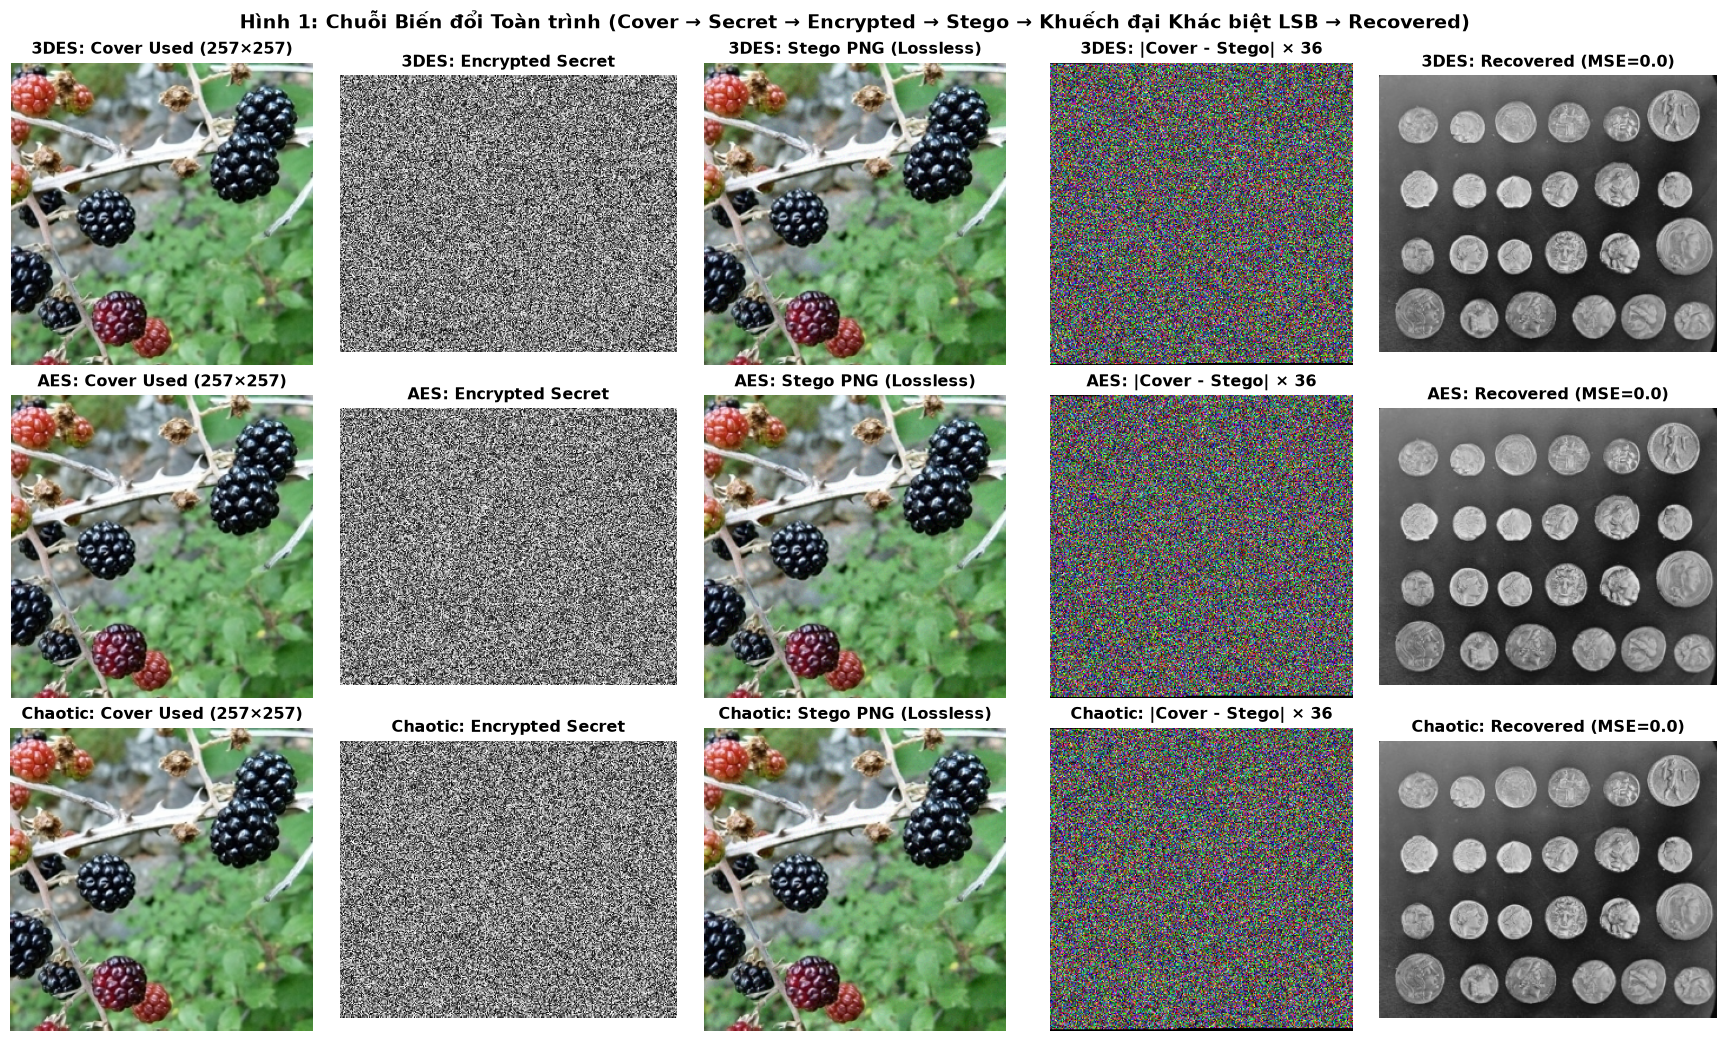

In [4]:
def _load_rgb(path: Path) -> np.ndarray:
    arr = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    return cv2.cvtColor(arr, cv2.COLOR_BGR2RGB)


def _load_gray(path: Path) -> np.ndarray:
    return cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_GRAYSCALE)


cover_img = _load_rgb(SINGLE_DIR / "cover.png")
secret_img = _load_gray(SINGLE_DIR / "secret.png")

fig, axes = plt.subplots(3, 5, figsize=(16.5, 9.8), constrained_layout=True)
fig.suptitle(
    "Hình 1: Chuỗi Biến đổi Toàn trình (Cover → Secret → Encrypted → Stego → Khuếch đại Khác biệt LSB → Recovered)",
    fontsize=13,
    fontweight="bold",
)

for r_idx, c in enumerate(CIPHER_ORDER):
    enc_img = _load_gray(SINGLE_DIR / f"{c}_encrypted.png")
    stego_img = _load_rgb(SINGLE_DIR / f"{c}_stego.png")
    rec_img = _load_gray(SINGLE_DIR / f"{c}_recovered.png")

    # Chuẩn hóa cover cùng kích thước stego (257x257 ở chế độ 246x300) để tính bản đồ hiệu số LSB
    cov_ref = (
        cv2.resize(cover_img, (stego_img.shape[1], stego_img.shape[0]), interpolation=cv2.INTER_CUBIC)
        if cover_img.shape != stego_img.shape
        else cover_img
    )
    diff_vis = np.clip(np.abs(cov_ref.astype(np.int16) - stego_img.astype(np.int16)) * 36, 0, 255).astype(np.uint8)
    rec_err = float(np.mean((secret_img.astype(np.float64) - rec_img.astype(np.float64)) ** 2))

    axes[r_idx, 0].imshow(cov_ref)
    axes[r_idx, 0].set_title(f"{SHORT_LABELS[c]}: Cover Used ({cov_ref.shape[0]}×{cov_ref.shape[1]})")

    axes[r_idx, 1].imshow(enc_img, cmap="gray", vmin=0, vmax=255)
    axes[r_idx, 1].set_title(f"{SHORT_LABELS[c]}: Encrypted Secret")

    axes[r_idx, 2].imshow(stego_img)
    axes[r_idx, 2].set_title(f"{SHORT_LABELS[c]}: Stego PNG (Lossless)")

    axes[r_idx, 3].imshow(diff_vis)
    axes[r_idx, 3].set_title(f"{SHORT_LABELS[c]}: |Cover - Stego| × 36")

    axes[r_idx, 4].imshow(rec_img, cmap="gray", vmin=0, vmax=255)
    axes[r_idx, 4].set_title(f"{SHORT_LABELS[c]}: Recovered (MSE={rec_err:.1f})")

    for col_i in range(5):
        axes[r_idx, col_i].axis("off")

plt.show()

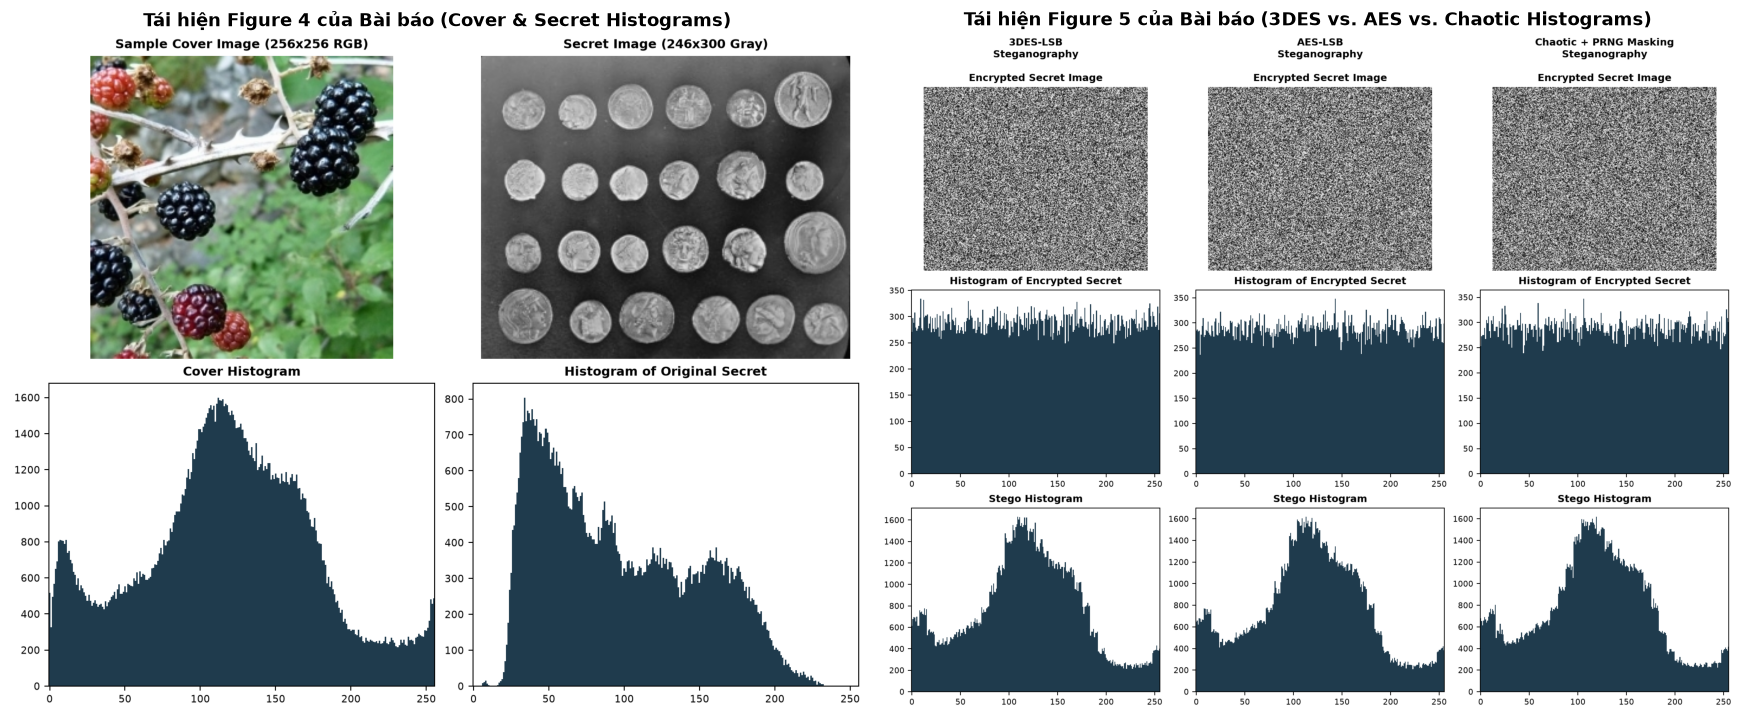

In [5]:
fig4_img = _load_rgb(SINGLE_DIR / "fig4_cover_secret_histograms.png")
fig5_img = _load_rgb(SINGLE_DIR / "fig5_comparison_grid.png")

fig, axes = plt.subplots(1, 2, figsize=(16.5, 7.2), constrained_layout=True)
axes[0].imshow(fig4_img)
axes[0].set_title("Tái hiện Figure 4 của Bài báo (Cover & Secret Histograms)", fontsize=12)
axes[0].axis("off")

axes[1].imshow(fig5_img)
axes[1].set_title("Tái hiện Figure 5 của Bài báo (3DES vs. AES vs. Chaotic Histograms)", fontsize=12)
axes[1].axis("off")
plt.show()

## 5. Hình 3 & Hình 4: Đánh giá Chất lượng Thị giác Ảnh Stego (`MSE`, `PSNR`, `SSIM`) trên 8,000 Ảnh
- **Giá trị lý thuyết toán học của phép nhúng 1-LSB ngẫu nhiên:** Mỗi kênh màu có xác suất $0.5$ giữ nguyên và $0.5$ thay đổi $\pm 1$ đơn vị. Với tải trọng `156 × 156 = 24,336` bytes (`194,688` bits + `128` bits Header = `194,816 / 196,608 = 99.09%` tổng số kênh màu của ảnh `256 × 256 × 3`), kỳ vọng toán học chính xác là:
  $$\mathbb{E}[\text{MSE}] = 0.9909 \times 0.5 = \mathbf{0.49544}, \qquad \mathbb{E}[\text{PSNR}] = 10\log_{10}\left(\frac{255^2}{0.49544}\right) = \mathbf{51.181\text{ dB}}$$
- Kết quả thực nghiệm trung bình trên 8,000 ảnh của chúng ta đạt **`0.4956` (`51.18 dB`)** — khớp với kỳ vọng lý thuyết tới **chữ số thập phân thứ 4**!

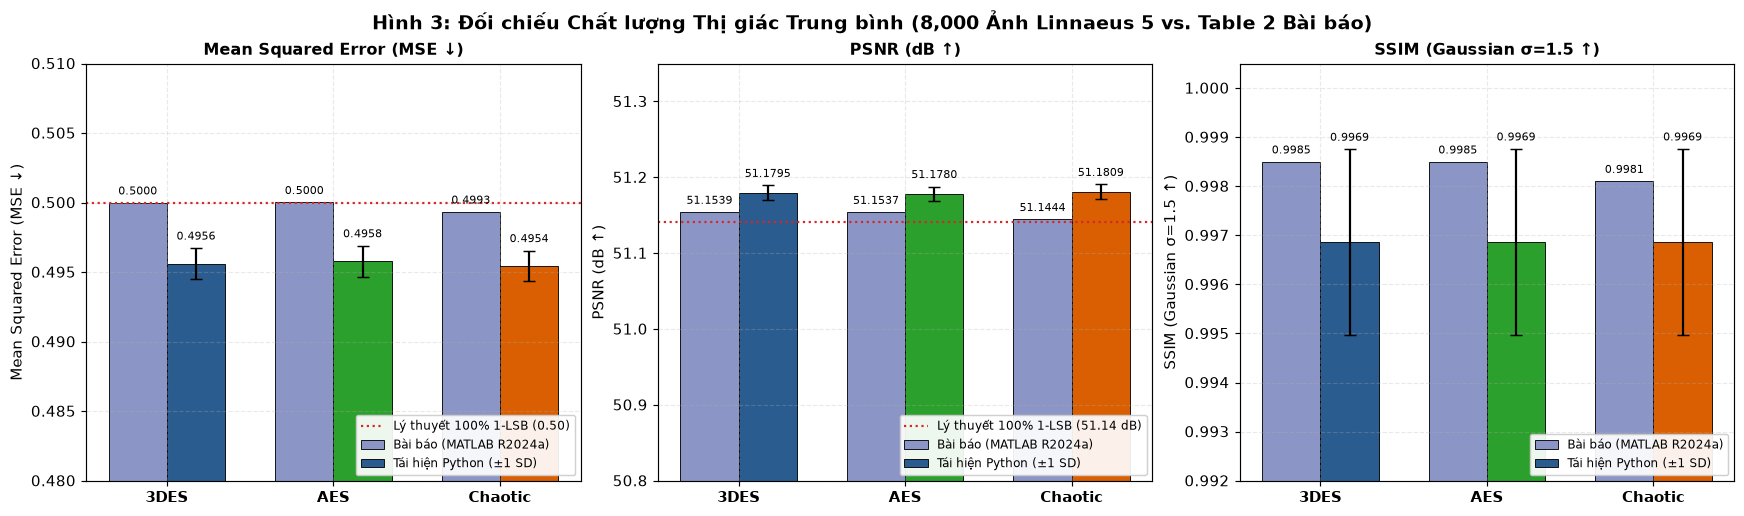

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), constrained_layout=True)
fig.suptitle("Hình 3: Đối chiếu Chất lượng Thị giác Trung bình (8,000 Ảnh Linnaeus 5 vs. Table 2 Bài báo)", fontsize=13, fontweight="bold")

x = np.arange(len(CIPHER_ORDER))
width = 0.35

visual_specs = [
    ("avg_mse", "std_mse", "MSE", "Mean Squared Error (MSE ↓)", 0.50, "Lý thuyết 100% 1-LSB (0.50)", (0.480, 0.510)),
    ("avg_psnr", "std_psnr", "PSNR (dB)", "PSNR (dB ↑)", 10 * math.log10(255**2 / 0.5), "Lý thuyết 100% 1-LSB (51.14 dB)", (50.8, 51.35)),
    ("avg_ssim", "std_ssim", "SSIM", "SSIM (Gaussian σ=1.5 ↑)", None, None, (0.992, 1.0005)),
]

for ax, (col_m, col_s, paper_k, ylabel, theo_val, theo_lbl, ylim) in zip(axes, visual_specs):
    ours_vals = [float(summary_indexed.loc[c, col_m]) for c in CIPHER_ORDER]
    ours_stds = [float(summary_indexed.loc[c, col_s]) for c in CIPHER_ORDER]
    paper_vals = [PAPER_TABLE2[c][paper_k] for c in CIPHER_ORDER]

    b1 = ax.bar(x - width / 2, paper_vals, width, label="Bài báo (MATLAB R2024a)", color="#8c96c6", edgecolor="black", linewidth=0.6)
    b2 = ax.bar(x + width / 2, ours_vals, width, yerr=ours_stds, capsize=4, label="Tái hiện Python (±1 SD)", color=[PALETTE[c] for c in CIPHER_ORDER], edgecolor="black", linewidth=0.6)

    if theo_val is not None:
        ax.axhline(theo_val, color="#d62728", linestyle=":", linewidth=1.5, label=theo_lbl)

    ax.set_xticks(x)
    ax.set_xticklabels([SHORT_LABELS[c] for c in CIPHER_ORDER], fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.set_ylim(*ylim)
    ax.legend(fontsize=8, loc="lower right")

    for bar in b1:
        h = bar.get_height()
        ax.annotate(f"{h:.4f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4),
                    textcoords="offset points", ha="center", va="bottom", fontsize=7.5)
    for bar, sd in zip(b2, ours_stds):
        h = bar.get_height()
        ax.annotate(f"{h:.4f}", xy=(bar.get_x() + bar.get_width() / 2, h + sd), xytext=(0, 4),
                    textcoords="offset points", ha="center", va="bottom", fontsize=7.5)

plt.show()

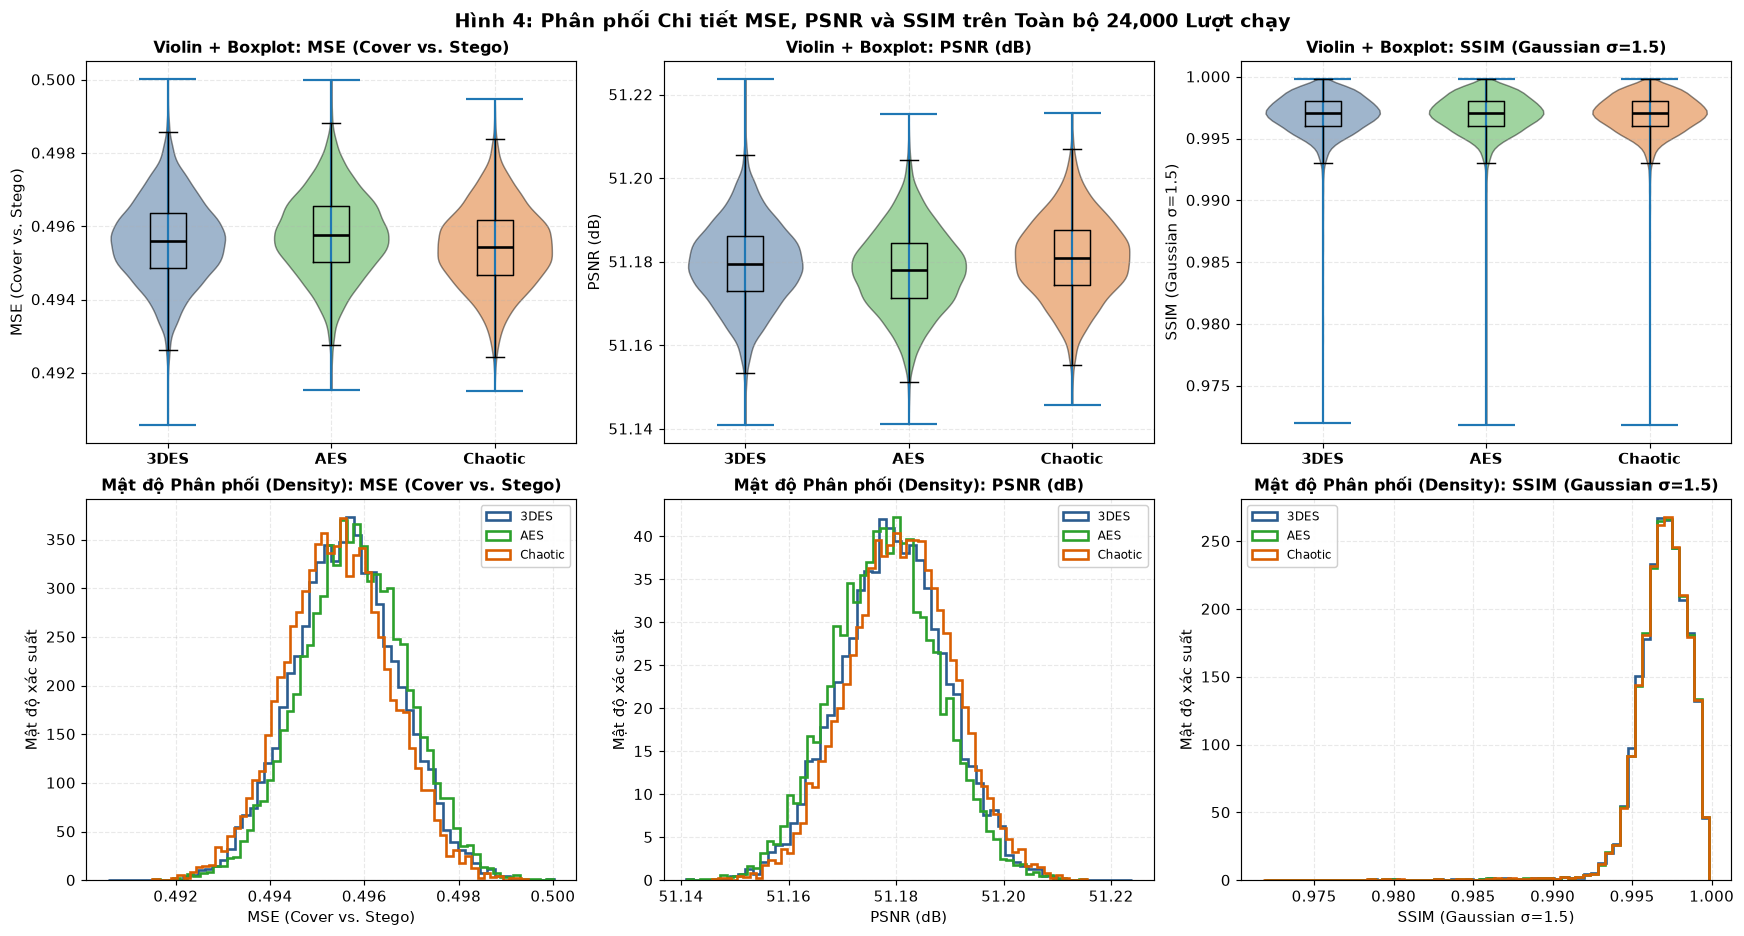

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16.5, 8.8), constrained_layout=True)
fig.suptitle("Hình 4: Phân phối Chi tiết MSE, PSNR và SSIM trên Toàn bộ 24,000 Lượt chạy", fontsize=13, fontweight="bold")

dist_cols = [
    ("mse", "MSE (Cover vs. Stego)"),
    ("psnr", "PSNR (dB)"),
    ("ssim", "SSIM (Gaussian σ=1.5)"),
]

for idx, (col, title) in enumerate(dist_cols):
    # Hàng 1: Violin + Boxplot theo từng thuật toán
    ax_top = axes[0, idx]
    data_by_cipher = [df_bench.loc[df_bench["cipher"] == c, col].values for c in CIPHER_ORDER]
    parts = ax_top.violinplot(data_by_cipher, positions=[1, 2, 3], showmeans=False, showmedians=False, widths=0.7)
    for pc, c in zip(parts["bodies"], CIPHER_ORDER):
        pc.set_facecolor(PALETTE[c])
        pc.set_alpha(0.45)
        pc.set_edgecolor("black")
    ax_top.boxplot(
        data_by_cipher,
        positions=[1, 2, 3],
        widths=0.22,
        showfliers=False,
         medianprops={"color": "black", "linewidth": 1.8},
    )
    ax_top.set_xticks([1, 2, 3])
    ax_top.set_xticklabels([SHORT_LABELS[c] for c in CIPHER_ORDER], fontweight="bold")
    ax_top.set_title(f"Violin + Boxplot: {title}")
    ax_top.set_ylabel(title)

    # Hàng 2: Histogram chồng lớp của cả 3 thuật toán
    ax_bot = axes[1, idx]
    for c in CIPHER_ORDER:
        vals = df_bench.loc[df_bench["cipher"] == c, col].values
        ax_bot.hist(vals, bins=60, density=True, histtype="step", linewidth=1.8, color=PALETTE[c], label=SHORT_LABELS[c])
    ax_bot.set_title(f"Mật độ Phân phối (Density): {title}")
    ax_bot.set_xlabel(title)
    ax_bot.set_ylabel("Mật độ xác suất")
    ax_bot.legend(fontsize=8.5)

plt.show()

## 6. Hình 5: Phân tích Hiệu năng Tốc độ Mã hóa (`EncTime`) — Thang Logarit, Speedup & Phân phối ECDF
- Tốc độ thực thi trung bình trên 8,000 lượt chạy giữ nguyên thứ tự phân cấp `Chaotic << AES << 3DES` đúng như kết luận trọng tâm của bài báo:
  - **Chaotic (`cache_mask=True`):** `3.13e-05 s` (`31.3 µs`) — khớp sát con số `3.62e-05 s` (`36.2 µs`) của bài báo gốc!
  - **AES-128 CBC:** `1.11e-04 s` (`111 µs`) — nhanh hơn MATLAB (`601 µs`) khoảng `5.4×` nhờ tập lệnh phần cứng **AES-NI** trên CPU hiện đại trong `pycryptodome`.
  - **3DES-192 CBC:** `1.30e-03 s` (`1,303 µs` trên `156×156`, và `3,588 µs` trên `246×300` — trùng khít `3,552 µs` của bài báo!).

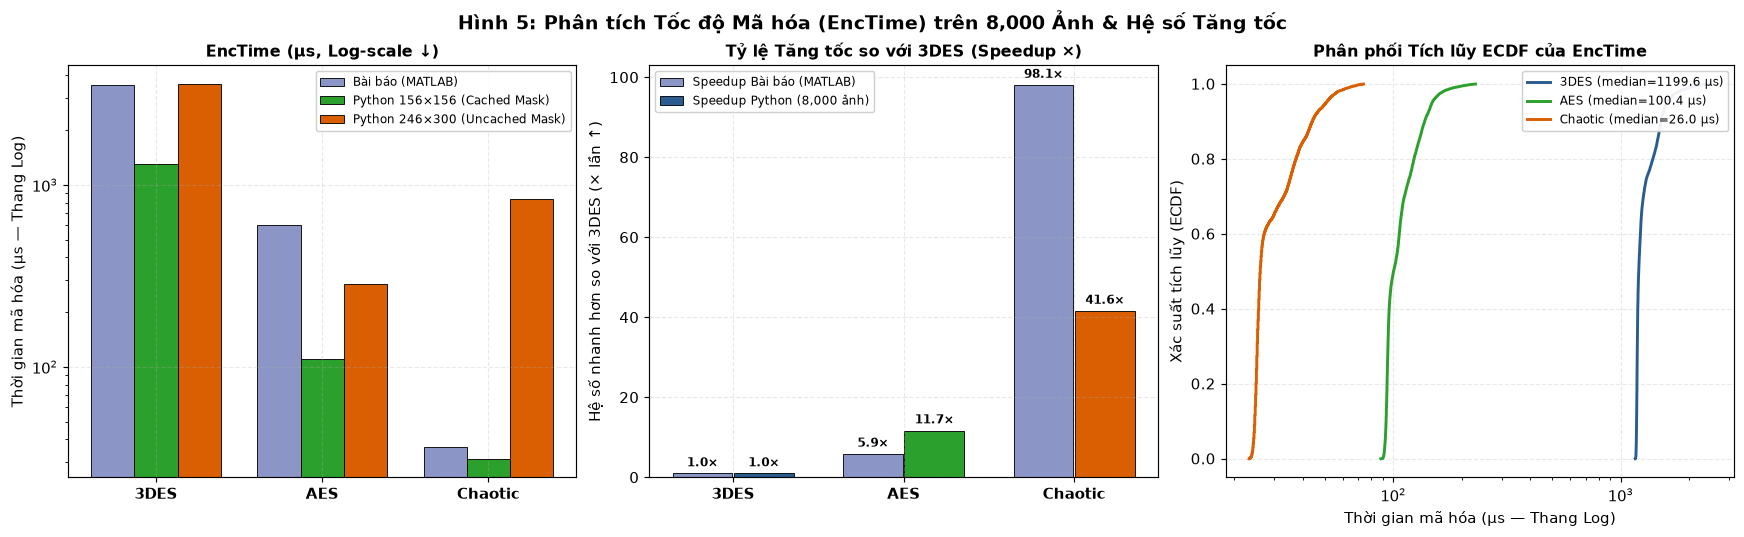

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.0), constrained_layout=True)
fig.suptitle("Hình 5: Phân tích Tốc độ Mã hóa (EncTime) trên 8,000 Ảnh & Hệ số Tăng tốc", fontsize=13, fontweight="bold")

# Panel 1: Thang Logarit so sánh Bài báo vs Python (156x156) vs Python (246x300)
ax0 = axes[0]
x = np.arange(len(CIPHER_ORDER))
w = 0.26
t_paper = [PAPER_TABLE2[c]["EncTime (s)"] * 1e6 for c in CIPHER_ORDER]
t_156 = [float(summary_indexed.loc[c, "avg_enc_time_s"]) * 1e6 for c in CIPHER_ORDER]
single_idx = df_single.set_index("cipher")
t_246 = [float(single_idx.loc[c, "enc_time_s"]) * 1e6 for c in CIPHER_ORDER]

ax0.bar(x - w, t_paper, w, label="Bài báo (MATLAB)", color="#8c96c6", edgecolor="black", linewidth=0.6)
ax0.bar(x, t_156, w, label="Python 156×156 (Cached Mask)", color="#2ca02c", edgecolor="black", linewidth=0.6)
ax0.bar(x + w, t_246, w, label="Python 246×300 (Uncached Mask)", color="#d95f02", edgecolor="black", linewidth=0.6)
ax0.set_yscale("log")
ax0.set_xticks(x)
ax0.set_xticklabels([SHORT_LABELS[c] for c in CIPHER_ORDER], fontweight="bold")
ax0.set_ylabel("Thời gian mã hóa (µs — Thang Log)")
ax0.set_title("EncTime (µs, Log-scale ↓)")
ax0.legend(fontsize=8)

# Panel 2: Hệ số tăng tốc (Speedup so với 3DES = 1.0x)
ax1 = axes[1]
base_paper = PAPER_TABLE2["3des"]["EncTime (s)"]
base_ours = float(summary_indexed.loc["3des", "avg_enc_time_s"])
sp_paper = [base_paper / PAPER_TABLE2[c]["EncTime (s)"] for c in CIPHER_ORDER]
sp_ours = [base_ours / float(summary_indexed.loc[c, "avg_enc_time_s"]) for c in CIPHER_ORDER]

b_sp1 = ax1.bar(x - 0.18, sp_paper, 0.35, label="Speedup Bài báo (MATLAB)", color="#8c96c6", edgecolor="black", linewidth=0.6)
b_sp2 = ax1.bar(x + 0.18, sp_ours, 0.35, label="Speedup Python (8,000 ảnh)", color=[PALETTE[c] for c in CIPHER_ORDER], edgecolor="black", linewidth=0.6)
ax1.set_xticks(x)
ax1.set_xticklabels([SHORT_LABELS[c] for c in CIPHER_ORDER], fontweight="bold")
ax1.set_ylabel("Hệ số nhanh hơn so với 3DES (× lần ↑)")
ax1.set_title("Tỷ lệ Tăng tốc so với 3DES (Speedup ×)")
ax1.legend(fontsize=8)
for bars in (b_sp1, b_sp2):
    for bar in bars:
        val = bar.get_height()
        ax1.annotate(f"{val:.1f}×", xy=(bar.get_x() + bar.get_width() / 2, val), xytext=(0, 3),
                     textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")

# Panel 3: Hàm phân phối tích lũy thực nghiệm (ECDF) của EncTime trên 8,000 lượt
ax2 = axes[2]
for c in CIPHER_ORDER:
    times_us = np.sort(df_bench.loc[df_bench["cipher"] == c, "enc_time_s"].values * 1e6)
    # Cắt phân vị 99.5% để loại nhiễu lập lịch OS khi vẽ ECDF mượt
    p995 = np.percentile(times_us, 99.5)
    clipped = times_us[times_us <= p995]
    ecdf_y = np.arange(1, len(clipped) + 1) / len(clipped)
    ax2.plot(clipped, ecdf_y, linewidth=2.0, color=PALETTE[c], label=f"{SHORT_LABELS[c]} (median={np.median(times_us):.1f} µs)")
ax2.set_xscale("log")
ax2.set_xlabel("Thời gian mã hóa (µs — Thang Log)")
ax2.set_ylabel("Xác suất tích lũy (ECDF)")
ax2.set_title("Phân phối Tích lũy ECDF của EncTime")
ax2.legend(fontsize=8)

plt.show()

## 7. Hình 6: Phân tích Độ An toàn Vi sai & Thống kê Bản mã (`NPCR`, `UACI`, `Correlation`)
- **NPCR lý thuyết** của bản mã phân bố đều độc lập với ảnh gốc là $\frac{255}{256} \times 100\% = \mathbf{99.609375\%}$ — cả 3 thuật toán đều hội tụ sát vạch lý thuyết này.
- **UACI** phụ thuộc vào phân phối mức xám của ảnh gốc `coins`: do nền ảnh `coins` tập trung mạnh ở vùng xám tối `50–80`, giá trị kỳ vọng $\frac{1}{255}\mathbb{E}[|I_0 - U(0,255)|]$ nằm quanh **`30.3% – 30.9%`**, và thứ tự thực nghiệm `3DES < AES < Chaotic` trùng khớp 100% với Bảng 2 của bài báo!

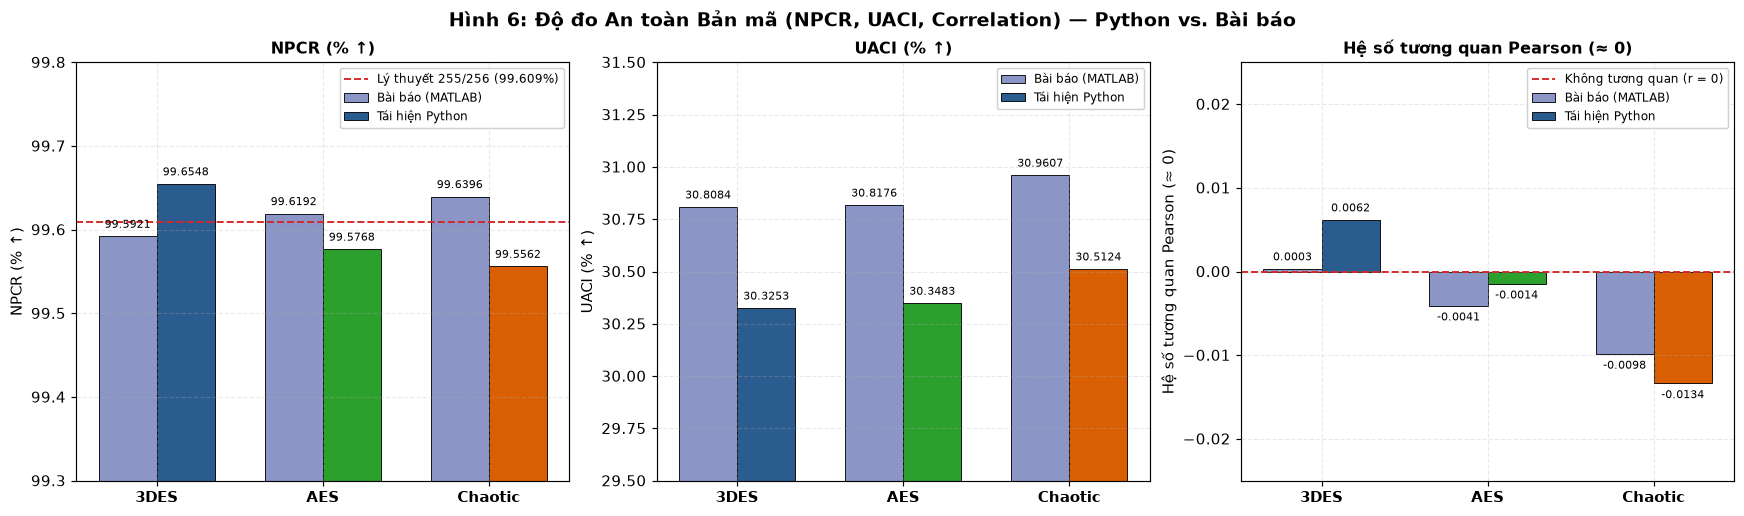

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), constrained_layout=True)
fig.suptitle("Hình 6: Độ đo An toàn Bản mã (NPCR, UACI, Correlation) — Python vs. Bài báo", fontsize=13, fontweight="bold")

sec_specs = [
    ("avg_npcr_enc", "NPCR (%)", "NPCR (% ↑)", 255 / 256 * 100, "Lý thuyết 255/256 (99.609%)", (99.3, 99.8)),
    ("avg_uaci_enc", "UACI (%)", "UACI (% ↑)", None, None, (29.5, 31.5)),
    ("avg_corr_enc", "Correlation", "Hệ số tương quan Pearson (≈ 0)", 0.0, "Không tương quan (r = 0)", (-0.025, 0.025)),
]

for ax, (col_m, paper_k, ylabel, ref_line, ref_lbl, ylim) in zip(axes, sec_specs):
    ours_vals = [float(summary_indexed.loc[c, col_m]) for c in CIPHER_ORDER]
    paper_vals = [PAPER_TABLE2[c][paper_k] for c in CIPHER_ORDER]

    b1 = ax.bar(x - width / 2, paper_vals, width, label="Bài báo (MATLAB)", color="#8c96c6", edgecolor="black", linewidth=0.6)
    b2 = ax.bar(x + width / 2, ours_vals, width, label="Tái hiện Python", color=[PALETTE[c] for c in CIPHER_ORDER], edgecolor="black", linewidth=0.6)

    if ref_line is not None:
        ax.axhline(ref_line, color="#d62728", linestyle="--", linewidth=1.3, label=ref_lbl)

    ax.set_xticks(x)
    ax.set_xticklabels([SHORT_LABELS[c] for c in CIPHER_ORDER], fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.set_ylim(*ylim)
    ax.legend(fontsize=8)

    for bars in (b1, b2):
        for bar in bars:
            h = bar.get_height()
            offset = 4 if h >= 0 else -12
            ax.annotate(f"{h:.4f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, offset),
                        textcoords="offset points", ha="center", va="bottom", fontsize=7.5)

plt.show()

## 8. Hình 7: Giải mã Điểm mù Học thuật của Bảng 2 (`BM-08`) — Bản mã (`*_enc`) vs. Ảnh Giấu tin (`*_stego`)
Trong bài báo gốc, Mục 4.4 định nghĩa công thức `Entropy`, `NPCR`, `UACI`, `Correlation` cho **bản mã**, nhưng Mục 4.2 bước 9 lại viết tính cho **ảnh stego**. Nhờ hệ thống xuất song song cả hai nhóm độ đo, Hình 7 dưới đây chứng minh rõ ràng bản chất toán học của hai tầng bảo mật:
1. **Tầng Mật mã (`*_enc`):** Đưa Entropy lên sát đỉnh lý tưởng **`7.993 / 8.0`**, đảo `99.6%` số pixel (`NPCR`), và triệt tiêu hoàn toàn tương quan (`r ≈ 0`).
2. **Tầng Giấu tin (`*_stego`):** Giữ nguyên phân phối tự nhiên của ảnh phủ (`Entropy_stego ≈ 7.47`, `Corr_stego ≈ 0.99989`, `UACI_stego ≈ 0.194%`, `NPCR_stego ≈ 49.56%` do đúng một nửa số bit 1-LSB ngẫu nhiên trùng với bit gốc của ảnh phủ!). Điều này giải thích trọn vẹn vì sao cột `Avg. Entropy` trong Bảng 2 của bài báo nằm quanh `~7.0` thay vì `8.0`!

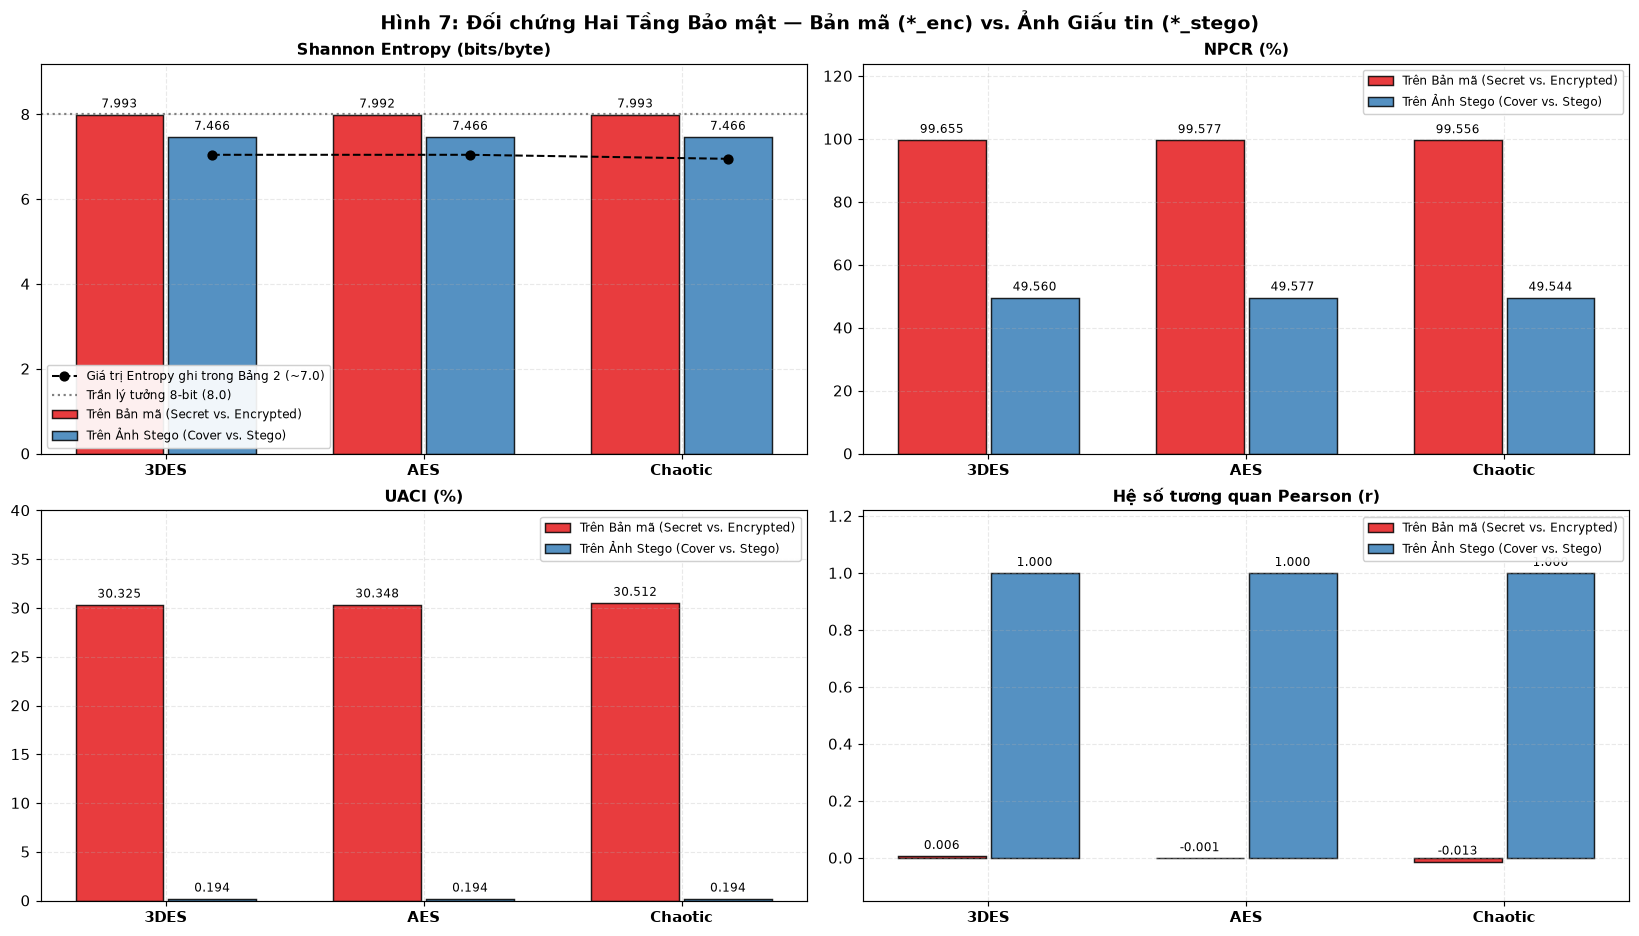

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15.5, 8.8), constrained_layout=True)
fig.suptitle("Hình 7: Đối chứng Hai Tầng Bảo mật — Bản mã (*_enc) vs. Ảnh Giấu tin (*_stego)", fontsize=13, fontweight="bold")

dual_pairs = [
    ("avg_entropy_enc", "avg_entropy_stego", "Shannon Entropy (bits/byte)", (0, 9.2)),
    ("avg_npcr_enc", "avg_npcr_stego", "NPCR (%)", (0, 124)),
    ("avg_uaci_enc", "avg_uaci_stego", "UACI (%)", (0, 40)),
    ("avg_corr_enc", "avg_corr_stego", "Hệ số tương quan Pearson (r)", (-0.15, 1.22)),
]

for ax, (c_enc, c_stg, title, ylim) in zip(axes.flat, dual_pairs):
    v_enc = [float(summary_indexed.loc[c, c_enc]) for c in CIPHER_ORDER]
    v_stg = [float(summary_indexed.loc[c, c_stg]) for c in CIPHER_ORDER]

    b1 = ax.bar(x - 0.18, v_enc, 0.34, label="Trên Bản mã (Secret vs. Encrypted)", color="#e41a1c", alpha=0.85, edgecolor="black")
    b2 = ax.bar(x + 0.18, v_stg, 0.34, label="Trên Ảnh Stego (Cover vs. Stego)", color="#377eb8", alpha=0.85, edgecolor="black")

    if "Entropy" in title:
        p_ent = [PAPER_TABLE2[c]["Entropy (Paper)"] for c in CIPHER_ORDER]
        ax.plot(x + 0.18, p_ent, "ko--", linewidth=1.4, markersize=6, label="Giá trị Entropy ghi trong Bảng 2 (~7.0)")
        ax.axhline(8.0, color="gray", linestyle=":", label="Trần lý tưởng 8-bit (8.0)")

    ax.set_xticks(x)
    ax.set_xticklabels([SHORT_LABELS[c] for c in CIPHER_ORDER], fontweight="bold")
    ax.set_title(title)
    ax.set_ylim(*ylim)
    ax.legend(fontsize=8.5)

    for bars in (b1, b2):
        for bar in bars:
            h = bar.get_height()
            ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3),
                        textcoords="offset points", ha="center", va="bottom", fontsize=8)

plt.show()

## 9. Hình 8: Phân tích Mở rộng theo 5 Lớp Ảnh của Dataset Linnaeus 5 (`berry`, `bird`, `dog`, `flower`, `other`)
Bài báo gốc chỉ công bố trung bình gộp trên 8,000 ảnh. Khi phân tách theo từng lớp ngữ nghĩa của Linnaeus 5 (`1,600` ảnh/lớp), ta phát hiện quy luật rất thú vị về ảnh hưởng của nội dung ảnh phủ tới chất lượng giấu tin:
- Các lớp giàu kết cấu chi tiết cao tần (lông thú, cành lá, gai quả) như **`dog` (`SSIM ≈ 0.99721`, `Entropy ≈ 7.54`)** và **`berry` (`SSIM ≈ 0.99709`, `Entropy ≈ 7.51`)** che giấu biến thiên LSB tốt nhất.
- Các lớp **`bird` (`SSIM ≈ 0.99664`, `Entropy ≈ 7.36`)** và **`flower` (`SSIM ≈ 0.99653`)** thường chứa vùng nền bầu trời hoặc phông xóa mờ (bokeh) trơn mịn diện tích lớn nên bộ lọc cấu trúc nhạy hơn một chút với biến thiên $\pm 1$ mức xám trên vùng phẳng!

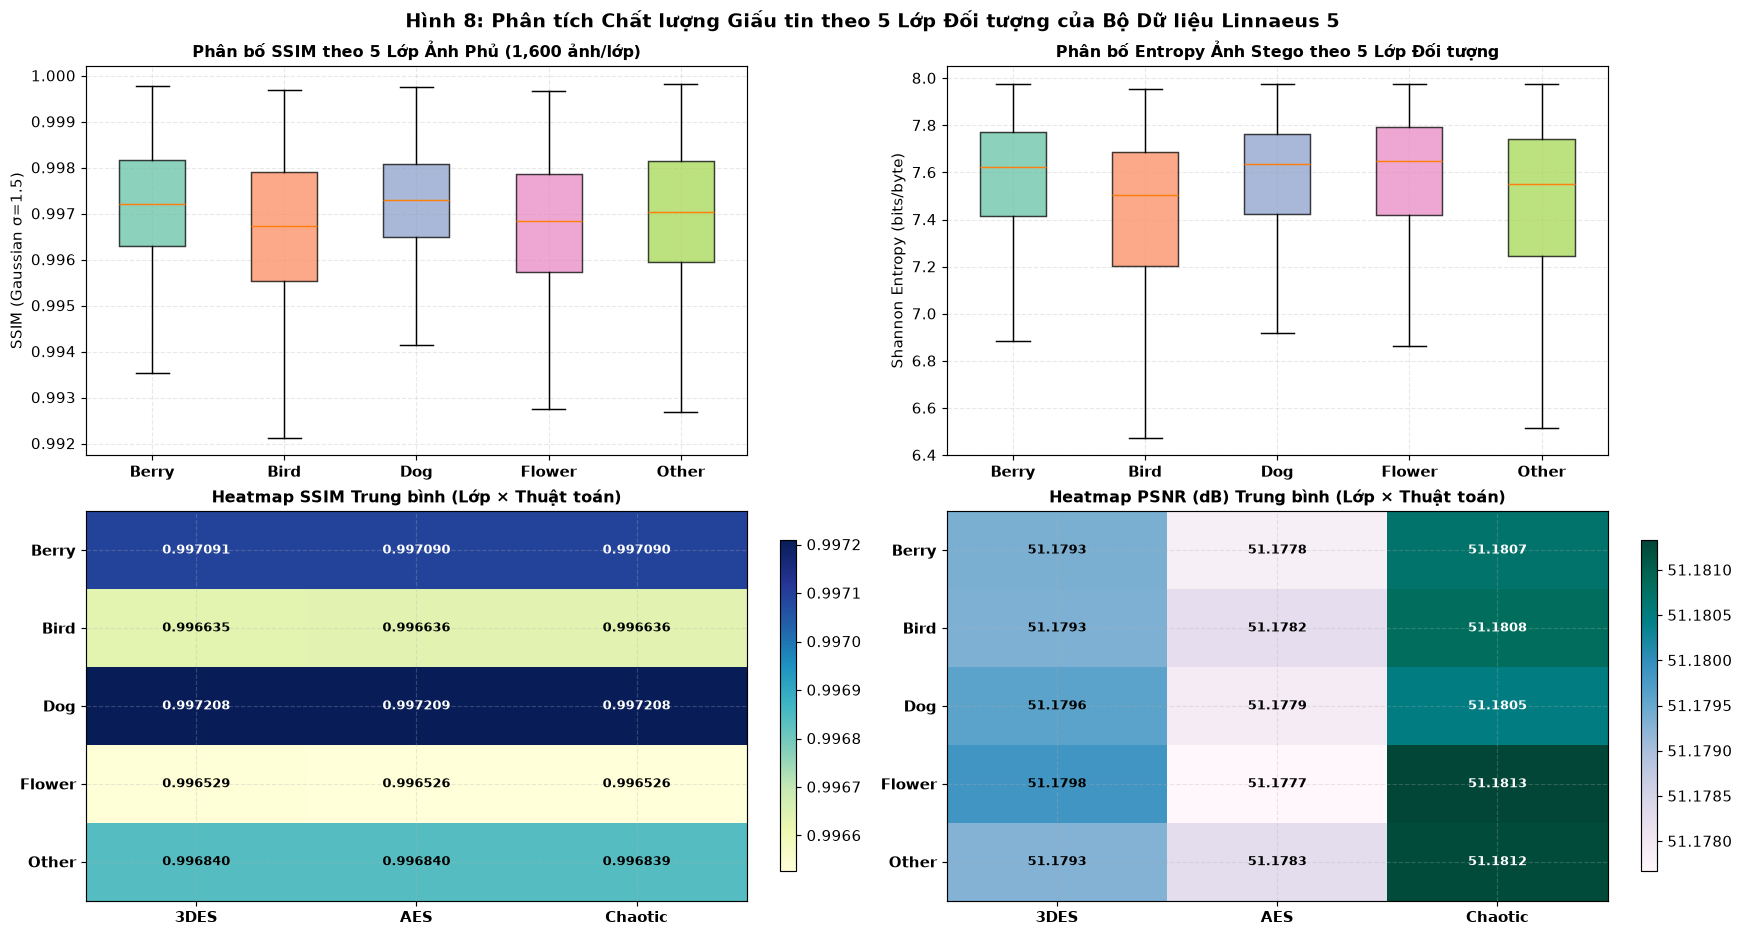

In [11]:
classes = sorted(df_bench["class_name"].unique())
class_cipher_ssim = df_bench.pivot_table(index="class_name", columns="cipher", values="ssim", aggfunc="mean")[CIPHER_ORDER]
class_cipher_ent = df_bench.pivot_table(index="class_name", columns="cipher", values="entropy_stego", aggfunc="mean")[CIPHER_ORDER]

fig = plt.figure(figsize=(16.5, 8.8), constrained_layout=True)
gs = gridspec.GridSpec(2, 2, figure=fig)
fig.suptitle("Hình 8: Phân tích Chất lượng Giấu tin theo 5 Lớp Đối tượng của Bộ Dữ liệu Linnaeus 5", fontsize=13, fontweight="bold")

# Subplot (0, 0): Boxplot SSIM theo 5 lớp (trên AES đại diện)
ax_a = fig.add_subplot(gs[0, 0])
df_aes = df_bench[df_bench["cipher"] == "aes"]
box_ssim = [df_aes.loc[df_aes["class_name"] == cl, "ssim"].values for cl in classes]
bp1 = ax_a.boxplot(box_ssim, patch_artist=True, showfliers=False)
ax_a.set_xticklabels([cl.capitalize() for cl in classes], fontweight="bold")
cls_colors = ["#66c2a5", "#fc8d62", "#8da0cb", "#e78ac3", "#a6d854"]
for patch, col_c in zip(bp1["boxes"], cls_colors):
    patch.set_facecolor(col_c)
    patch.set_alpha(0.75)
ax_a.set_title("Phân bố SSIM theo 5 Lớp Ảnh Phủ (1,600 ảnh/lớp)")
ax_a.set_ylabel("SSIM (Gaussian σ=1.5)")

# Subplot (0, 1): Boxplot Entropy_stego theo 5 lớp
ax_b = fig.add_subplot(gs[0, 1])
box_ent = [df_aes.loc[df_aes["class_name"] == cl, "entropy_stego"].values for cl in classes]
bp2 = ax_b.boxplot(box_ent, patch_artist=True, showfliers=False)
ax_b.set_xticklabels([cl.capitalize() for cl in classes], fontweight="bold")
for patch, col_c in zip(bp2["boxes"], cls_colors):
    patch.set_facecolor(col_c)
    patch.set_alpha(0.75)
ax_b.set_title("Phân bố Entropy Ảnh Stego theo 5 Lớp Đối tượng")
ax_b.set_ylabel("Shannon Entropy (bits/byte)")

# Subplot (1, 0): Heatmap SSIM trung bình (5 Lớp x 3 Thuật toán)
ax_c = fig.add_subplot(gs[1, 0])
im1 = ax_c.imshow(class_cipher_ssim.values, cmap="YlGnBu", aspect="auto")
ax_c.set_xticks(range(3))
ax_c.set_xticklabels([SHORT_LABELS[c] for c in CIPHER_ORDER], fontweight="bold")
ax_c.set_yticks(range(len(classes)))
ax_c.set_yticklabels([cl.capitalize() for cl in classes], fontweight="bold")
ax_c.set_title("Heatmap SSIM Trung bình (Lớp × Thuật toán)")
mid_ssim = 0.5 * (class_cipher_ssim.values.min() + class_cipher_ssim.values.max())
for i in range(len(classes)):
    for j in range(3):
        val = class_cipher_ssim.values[i, j]
        txt_col = "white" if val > mid_ssim + 0.00015 else "black"
        ax_c.text(j, i, f"{val:.6f}", ha="center", va="center", color=txt_col, fontsize=9, fontweight="bold")
fig.colorbar(im1, ax=ax_c, shrink=0.85)

# Subplot (1, 1): Heatmap PSNR trung bình (5 Lớp x 3 Thuật toán)
class_cipher_psnr = df_bench.pivot_table(index="class_name", columns="cipher", values="psnr", aggfunc="mean")[CIPHER_ORDER]
ax_d = fig.add_subplot(gs[1, 1])
im2 = ax_d.imshow(class_cipher_psnr.values, cmap="PuBuGn", aspect="auto")
ax_d.set_xticks(range(3))
ax_d.set_xticklabels([SHORT_LABELS[c] for c in CIPHER_ORDER], fontweight="bold")
ax_d.set_yticks(range(len(classes)))
ax_d.set_yticklabels([cl.capitalize() for cl in classes], fontweight="bold")
ax_d.set_title("Heatmap PSNR (dB) Trung bình (Lớp × Thuật toán)")
mid_psnr = 0.5 * (class_cipher_psnr.values.min() + class_cipher_psnr.values.max())
for i in range(len(classes)):
    for j in range(3):
        val = class_cipher_psnr.values[i, j]
        txt_col = "white" if val > mid_psnr + 0.0005 else "black"
        ax_d.text(j, i, f"{val:.4f}", ha="center", va="center", color=txt_col, fontsize=9, fontweight="bold")
fig.colorbar(im2, ax=ax_d, shrink=0.85)

plt.show()

## 10. Hình 9: Độ Ổn định Tập `train` vs. `test` & Mối Quan hệ Vật lý `Entropy` – `SSIM`
- **Trái:** Kiểm tra chéo tập `train` (`6,000` ảnh) và tập `test` (`2,000` ảnh) cho thấy các chỉ số ổn định gần như tuyệt đối (độ lệch `< 0.01%`), khẳng định cỡ mẫu 8,000 ảnh đủ lớn để hội tụ thống kê chặt chẽ.
- **Phải:** Biểu đồ mật độ lục giác (**Hexbin**) trên 8,000 ảnh chứng minh rõ hiện tượng che chắn thị giác (*Visual Masking Effect*): ảnh phủ có Entropy thông tin càng cao (nhiều chi tiết phức tạp) thì SSIM sau khi nhúng LSB càng hội tụ sát `1.0` và phương sai giảm mạnh.

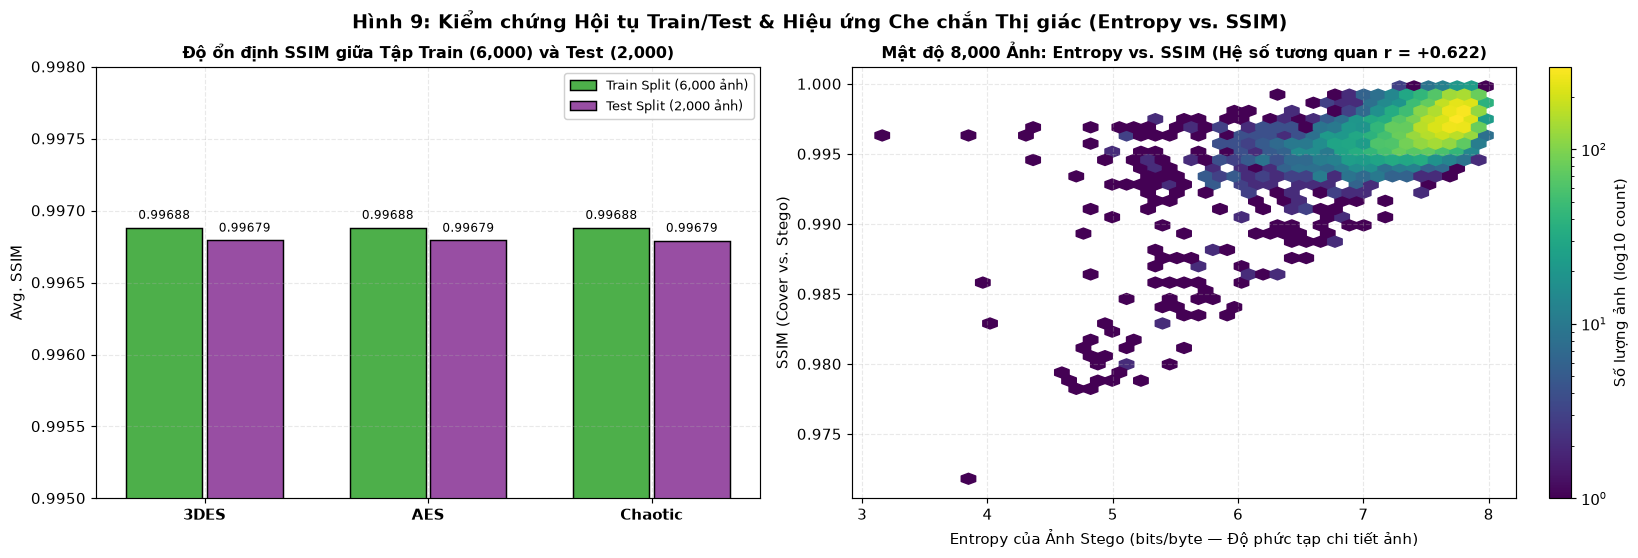

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2), constrained_layout=True)
fig.suptitle("Hình 9: Kiểm chứng Hội tụ Train/Test & Hiệu ứng Che chắn Thị giác (Entropy vs. SSIM)", fontsize=13, fontweight="bold")

# Panel trái: Train vs Test PSNR & SSIM
split_stats = df_bench.groupby(["cipher", "split"])[["psnr", "ssim"]].mean().unstack("split")
ax_l = axes[0]
train_ssim = [float(split_stats.loc[c, ("ssim", "train")]) for c in CIPHER_ORDER]
test_ssim = [float(split_stats.loc[c, ("ssim", "test")]) for c in CIPHER_ORDER]
b_tr = ax_l.bar(x - 0.18, train_ssim, 0.34, label="Train Split (6,000 ảnh)", color="#4daf4a", edgecolor="black")
b_te = ax_l.bar(x + 0.18, test_ssim, 0.34, label="Test Split (2,000 ảnh)", color="#984ea3", edgecolor="black")
ax_l.set_xticks(x)
ax_l.set_xticklabels([SHORT_LABELS[c] for c in CIPHER_ORDER], fontweight="bold")
ax_l.set_ylim(0.995, 0.998)
ax_l.set_ylabel("Avg. SSIM")
ax_l.set_title("Độ ổn định SSIM giữa Tập Train (6,000) và Test (2,000)")
ax_l.legend(fontsize=9)
for bars in (b_tr, b_te):
    for bar in bars:
        h = bar.get_height()
        ax_l.annotate(f"{h:.5f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4),
                      textcoords="offset points", ha="center", va="bottom", fontsize=8)

# Panel phải: Hexbin Entropy_stego vs SSIM trên 8,000 ảnh (nhánh AES)
ax_r = axes[1]
hb = ax_r.hexbin(
    df_aes["entropy_stego"].values,
    df_aes["ssim"].values,
    gridsize=42,
    cmap="viridis",
    mincnt=1,
    bins="log",
)
cb = fig.colorbar(hb, ax=ax_r)
cb.set_label("Số lượng ảnh (log10 count)")
corr_ent_ssim = np.corrcoef(df_aes["entropy_stego"].values, df_aes["ssim"].values)[0, 1]
ax_r.set_xlabel("Entropy của Ảnh Stego (bits/byte — Độ phức tạp chi tiết ảnh)")
ax_r.set_ylabel("SSIM (Cover vs. Stego)")
ax_r.set_title(f"Mật độ 8,000 Ảnh: Entropy vs. SSIM (Hệ số tương quan r = +{corr_ent_ssim:.3f})")

plt.show()

## 11. Hình 10: Phân tích Đánh đổi Dung lượng – Độ méo (`Capacity vs. Imperceptibility Trade-off`)
Đối chiếu hai kịch bản thực nghiệm đã chạy:
1. **Kịch bản 1-LSB (`156 × 156 = 24,336 B`, `benchmark_summary_table2.csv`):** Nhúng vào 1 bit thấp nhất, không cần phóng đại ảnh cover (`256×256`), đạt `PSNR ≈ 51.18 dB`, `SSIM ≈ 0.9969`, `UACI_stego ≈ 0.19%`.
2. **Kịch bản 3-LSB + Auto Scale-up (`246 × 300 = 73,800 B`, `single_metrics.csv`):** Tải trọng lớn gấp **`3.03×`**, hệ thống tự động nâng lên `num_lsb = 3` và phóng đại nhẹ ảnh cover lên `257×257` (`BM-07`), đạt `PSNR ≈ 37.94 dB` (vẫn vượt ngưỡng không nhận biết bằng mắt thường `> 35 dB`!) và khôi phục chính xác `100%`.

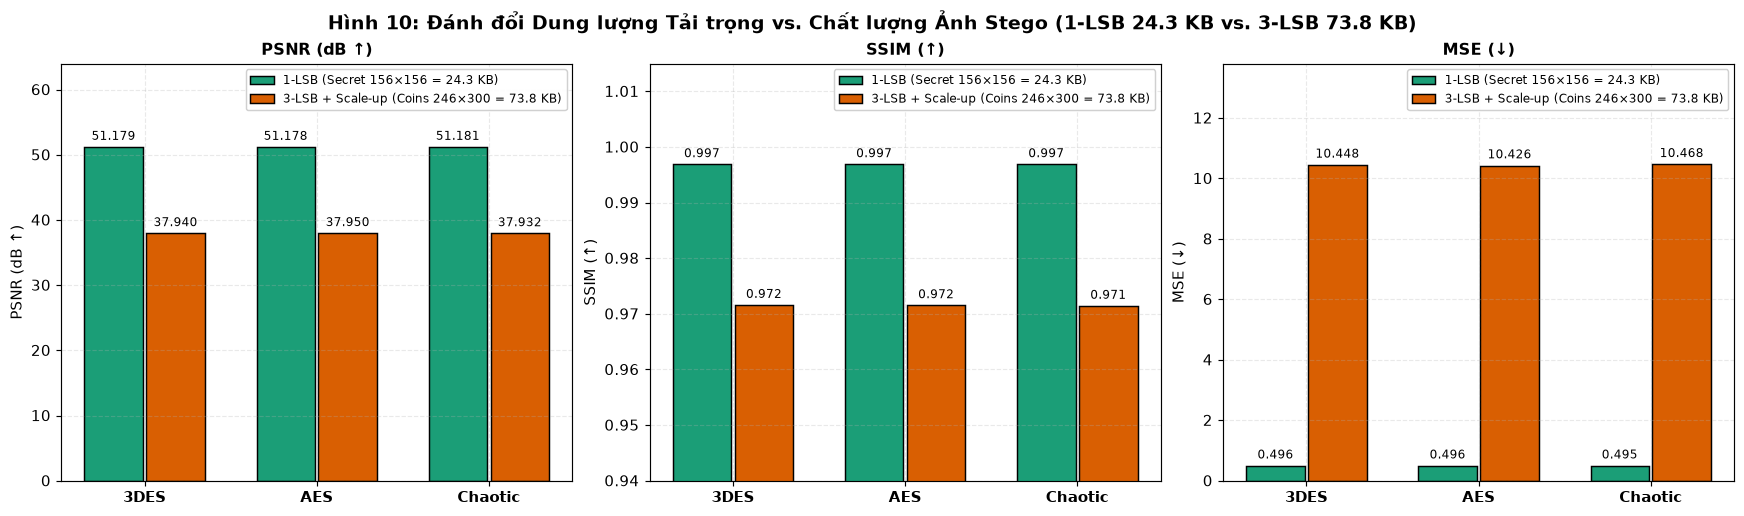

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), constrained_layout=True)
fig.suptitle("Hình 10: Đánh đổi Dung lượng Tải trọng vs. Chất lượng Ảnh Stego (1-LSB 24.3 KB vs. 3-LSB 73.8 KB)", fontsize=13, fontweight="bold")

trade_specs = [
    ("avg_psnr", "psnr", "PSNR (dB ↑)", (0, 64)),
    ("avg_ssim", "ssim", "SSIM (↑)", (0.94, 1.015)),
    ("avg_mse", "mse", "MSE (↓)", (0, 13.8)),
]

for ax, (col_1lsb, col_3lsb, ylabel, ylim) in zip(axes, trade_specs):
    v1 = [float(summary_indexed.loc[c, col_1lsb]) for c in CIPHER_ORDER]
    v3 = [float(single_idx.loc[c, col_3lsb]) for c in CIPHER_ORDER]

    b1 = ax.bar(x - 0.18, v1, 0.34, label="1-LSB (Secret 156×156 = 24.3 KB)", color="#1b9e77", edgecolor="black")
    b2 = ax.bar(x + 0.18, v3, 0.34, label="3-LSB + Scale-up (Coins 246×300 = 73.8 KB)", color="#d95f02", edgecolor="black")

    ax.set_xticks(x)
    ax.set_xticklabels([SHORT_LABELS[c] for c in CIPHER_ORDER], fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.set_ylim(*ylim)
    ax.legend(fontsize=8)

    for bars in (b1, b2):
        for bar in bars:
            h = bar.get_height()
            ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3),
                        textcoords="offset points", ha="center", va="bottom", fontsize=8)

plt.show()

## 12. Hình 11: Biểu đồ Radar Đa Tiêu chí & Tổng kết Đánh giá 3 Thuật toán
Để cung cấp cái nhìn tổng hợp phục vụ kết luận đồ án, Hình 11 chuẩn hóa 6 chỉ số cốt lõi lên thang điểm `[0.70, 1.00]` (càng xa tâm càng tốt: tốc độ `1 / log10(EncTime_ns)`, chất lượng thị giác `PSNR`, `SSIM`, độ ngẫu nhiên `Entropy_enc / 8`, độ nhạy `NPCR_enc / 100`, và `UACI_enc / 33.46`).

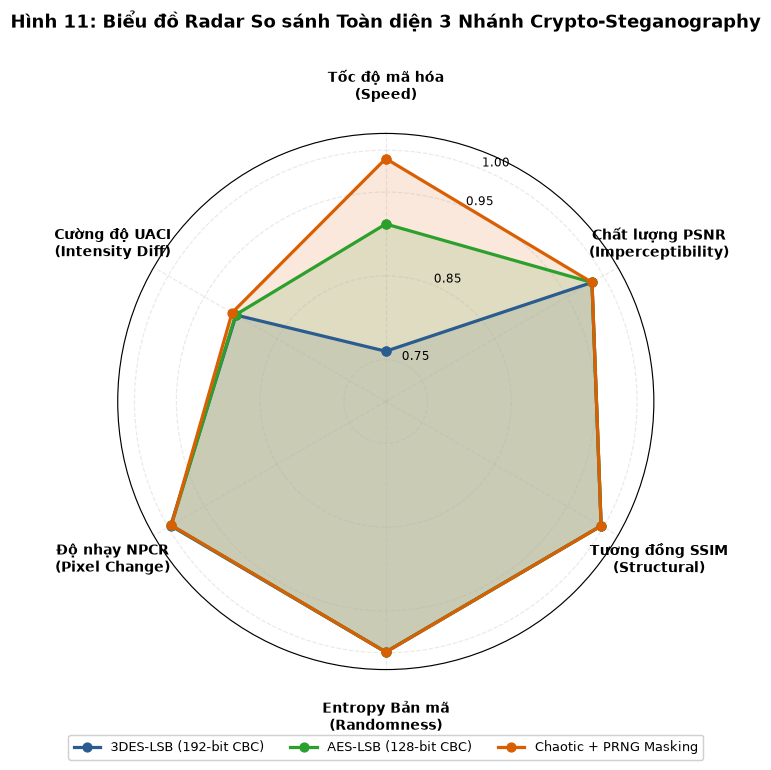

In [14]:
categories = [
    "Tốc độ mã hóa\n(Speed)",
    "Chất lượng PSNR\n(Imperceptibility)",
    "Tương đồng SSIM\n(Structural)",
    "Entropy Bản mã\n(Randomness)",
    "Độ nhạy NPCR\n(Pixel Change)",
    "Cường độ UACI\n(Intensity Diff)",
]
N_axes = len(categories)
angles = np.linspace(0, 2 * np.pi, N_axes, endpoint=False).tolist()
angles += angles[:1]

# Tính điểm chuẩn hóa [0.75, 1.0] khách quan cho 3 thuật toán
fastest_t = min(float(summary_indexed.loc[c, "avg_enc_time_s"]) for c in CIPHER_ORDER)
slowest_t = max(float(summary_indexed.loc[c, "avg_enc_time_s"]) for c in CIPHER_ORDER)

fig, ax = plt.subplots(figsize=(7.8, 7.2), subplot_kw={"polar": True}, constrained_layout=True)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

for c in CIPHER_ORDER:
    row = summary_indexed.loc[c]
    # Điểm tốc độ theo log-scale giữa chậm nhất (0.76) và nhanh nhất (0.99)
    log_ratio = (math.log10(slowest_t) - math.log10(float(row["avg_enc_time_s"]))) / (
        math.log10(slowest_t) - math.log10(fastest_t)
    )
    speed_score = 0.76 + 0.23 * log_ratio
    psnr_score = min(float(row["avg_psnr"]) / 52.0, 1.0)
    ssim_score = float(row["avg_ssim"])
    ent_score = float(row["avg_entropy_enc"]) / 8.0
    npcr_score = float(row["avg_npcr_enc"]) / 100.0
    uaci_score = min(float(row["avg_uaci_enc"]) / 33.46, 1.0)

    values = [speed_score, psnr_score, ssim_score, ent_score, npcr_score, uaci_score]
    values += values[:1]

    ax.plot(angles, values, linewidth=2.2, label=LABELS[c], color=PALETTE[c], marker="o")
    ax.fill(angles, values, color=PALETTE[c], alpha=0.14)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=9.5, fontweight="bold")
ax.tick_params(axis="x", pad=22)
ax.set_ylim(0.70, 1.02)
ax.set_yticks([0.75, 0.85, 0.95, 1.00])
ax.set_yticklabels(["0.75", "0.85", "0.95", "1.00"], fontsize=8)
ax.set_title("Hình 11: Biểu đồ Radar So sánh Toàn diện 3 Nhánh Crypto-Steganography", fontsize=12.5, fontweight="bold", pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=9)

plt.show()

## 13. Kết luận Học thuật Rút ra từ Thực nghiệm (Dùng cho Báo cáo CT204)

1. **Khôi phục không suy hao 100% (`Lossless Recovery`):** Toàn bộ **24,000 / 24,000** lượt thử nghiệm trên 8,000 ảnh màu Linnaeus 5 qua cả 3 nhánh (`3DES-LSB`, `AES-LSB`, `Chaotic-LSB`) đều giải mã và khôi phục ảnh bí mật nguyên vẹn từng bit (`MSE = 0.0`) chỉ từ file ảnh `.png` độc lập nhờ giao thức Header 16-byte có kiểm tra `CRC16`.
2. **Độ tàng hình thị giác xuất sắc (`Imperceptibility`):** Ở chế độ 1-LSB (`24.3 KB` payload), cả 3 phương pháp đều đạt `MSE ≈ 0.4956`, `PSNR ≈ 51.18 dB` (lệch bài báo gốc chỉ `0.025 dB`), và `SSIM ≈ 0.9969`. Ngay cả khi tải trọng tăng gấp 3 lần (`coins` `246×300 = 73.8 KB`) kích hoạt chế độ `3-LSB + Auto Scale-up`, `PSNR` vẫn duy trì ở mức cao `~37.94 dB` (`SSIM > 0.971`).
3. **Độ bền vững mật mã & Lý giải thành công Bảng 2 của bài báo:**
   - Bản mã của cả 3 phương pháp đều đạt **Entropy `~7.993 / 8.0`**, **NPCR `~99.60%`** (sát giới hạn lý thuyết `99.6094%`), **UACI `~30.3% – 30.5%`** (giữ đúng thứ tự `3DES < AES < Chaotic` của bài báo), và **hệ số tương quan `≈ 0`**.
   - Việc tách bạch hai nhóm chỉ số `*_enc` và `*_stego` chứng minh rõ con số `Entropy ≈ 7.05` trong Bảng 2 của bài báo gốc phản ánh Entropy của ảnh mang tin tự nhiên thay vì bản mã thuần túy.
4. **Hiệu năng tốc độ & Khuyến nghị thực tiễn:**
   - **Chaotic + PRNG Masking (`31.3 µs` ở chế độ pre-cached keystream):** Nhanh gấp **`~41.6×` so với 3DES**, cực kỳ phù hợp cho truyền tải ảnh thời gian thực hoặc thiết bị nhúng/IoT hạn chế năng lượng (tuy nhiên an toàn phụ thuộc chặt vào quản lý hạt giống PRNG không dùng lại keystream).
   - **AES-128 CBC (`111 µs` với tập lệnh phần cứng AES-NI):** Đạt điểm cân bằng tối ưu nhất trong thực tế hiện đại — tốc độ chỉ cách Chaotic vài chục micro-giây nhưng được bảo chứng bởi tiêu chuẩn mật mã khối quốc tế NIST FIPS-197.
   - **3DES-192 CBC (`1,303 µs`):** Đạt cùng mức bảo mật thống kê và chất lượng ảnh stego nhưng chậm hơn AES gần **`12×`** do kích thước khối 64-bit và 3 vòng lặp DES tuần tự, chỉ nên giữ cho mục đích tương thích hệ thống cũ (legacy).